# KNN Klasifikasi BISINDO (k=7)
Fitur: 127-dim MediaPipe Hand Landmarks | 26 Kelas Alfabet

## 1. Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings,os,time,json
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split,StratifiedKFold,cross_val_score
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix
from sklearn.pipeline import Pipeline
warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi']=120
print('KNN k=7 siap')

KNN k=7 siap


## 2. Load Dataset

In [2]:
DATA_PATH=r"E:\\Dokumen\\Kuliah\\Semester 5\\Pembelajaran Mesin\\Klasifikasi_Kelompok_1\\dataset_bisindo_landmarks.npz"
OUTPUT_DIR=r"E:\\Dokumen\\Kuliah\\Semester 5\\Pembelajaran Mesin\\Klasifikasi_Kelompok_1\\KNN\\knn_k7\\outputKNN"
os.makedirs(OUTPUT_DIR,exist_ok=True)
data=np.load(DATA_PATH,allow_pickle=True)
X=np.nan_to_num(data['X'].astype(np.float32))
labels=data['labels']
le=LabelEncoder()
y=le.fit_transform(labels)
class_names=le.classes_
print(f'X.shape={X.shape}, n_classes={len(class_names)}')

X.shape=(7893, 127), n_classes=26


## 3. Visualisasi Distribusi

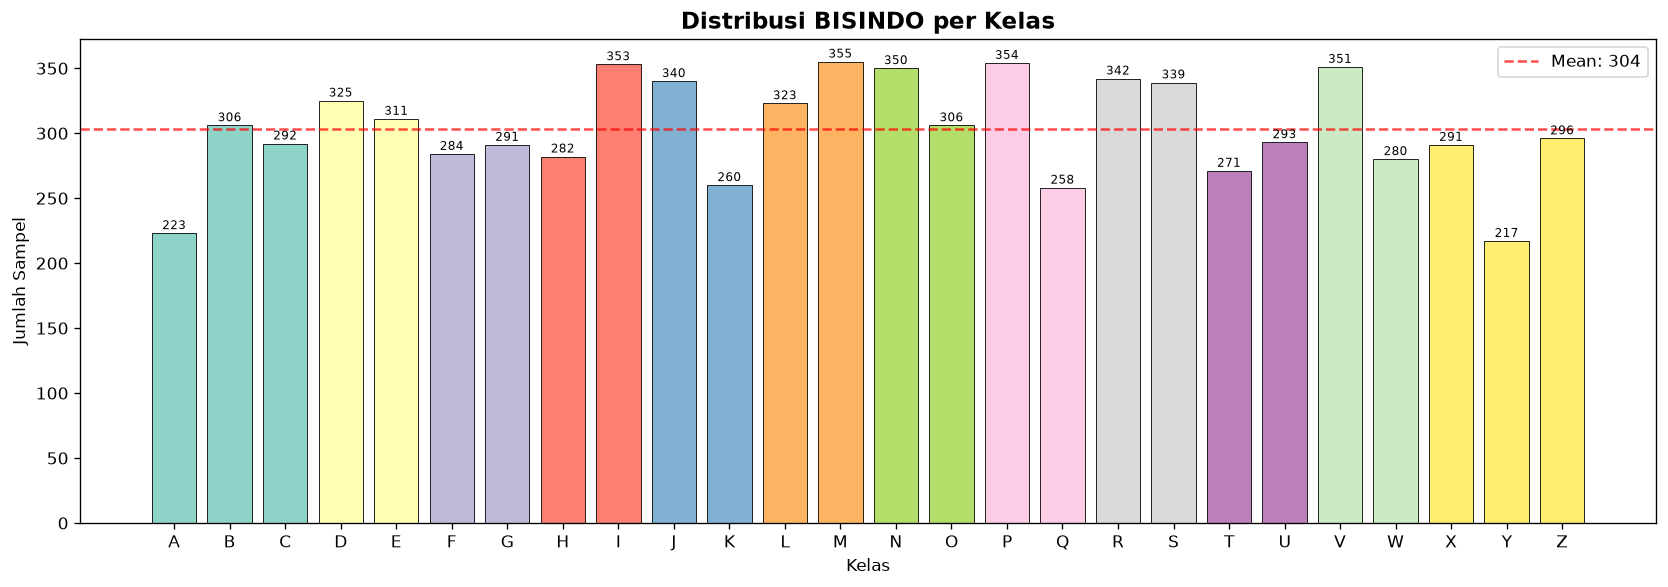

In [3]:
unique,counts=np.unique(y,return_counts=True)
fig,ax=plt.subplots(figsize=(14,5))
clrs=plt.cm.Set3(np.linspace(0,1,len(class_names)))
bars=ax.bar(class_names,counts,color=clrs,edgecolor='black',lw=0.5)
for b,c in zip(bars,counts): ax.text(b.get_x()+b.get_width()/2,b.get_height()+1,str(c),ha='center',va='bottom',fontsize=7)
ax.axhline(counts.mean(),color='red',ls='--',alpha=0.7,label=f'Mean: {counts.mean():.0f}')
ax.set_title('Distribusi BISINDO per Kelas',fontsize=14,fontweight='bold')
ax.set_xlabel('Kelas');ax.set_ylabel('Jumlah Sampel');ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'distribusi_knn_k7.png'),dpi=150,bbox_inches='tight')
plt.show()

## 4. Preprocessing & Split

In [4]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler=StandardScaler()
X_tr=scaler.fit_transform(X_train)
X_te=scaler.transform(X_test)
print(f'Train={X_tr.shape[0]}, Test={X_te.shape[0]}, Features={X_tr.shape[1]}')

Train=6314, Test=1579, Features=127


## 5. Training KNN (k=7)

In [5]:
knn=KNeighborsClassifier(n_neighbors=7,metric='euclidean',weights='distance',algorithm='ball_tree',n_jobs=-1)
t0=time.time();knn.fit(X_tr,y_train);train_time=time.time()-t0
print(f'Training selesai: {train_time:.2f}s | k=7')

Training selesai: 0.07s | k=7


## 6. Evaluasi

In [6]:
t0=time.time();y_pred=knn.predict(X_te);pred_time=time.time()-t0
accuracy=accuracy_score(y_test,y_pred)
precision=precision_score(y_test,y_pred,average='weighted',zero_division=0)
recall=recall_score(y_test,y_pred,average='weighted',zero_division=0)
f1=f1_score(y_test,y_pred,average='weighted',zero_division=0)
print('='*50)
print(f'EVALUASI KNN k=7')
print('='*50)
print(f'Accuracy   : {accuracy:.4f} ({accuracy*100:.2f}%)')
print(f'Precision  : {precision:.4f}')
print(f'Recall     : {recall:.4f}')
print(f'F1-Score   : {f1:.4f}')

EVALUASI KNN k=7
Accuracy   : 0.9506 (95.06%)
Precision  : 0.9513
Recall     : 0.9506
F1-Score   : 0.9503


## 7. Cross-Validation 5-Fold

In [7]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
pipe=Pipeline([('sc',StandardScaler()),('knn',KNeighborsClassifier(n_neighbors=7,metric='euclidean',weights='distance',n_jobs=-1))])
cv_scores=cross_val_score(pipe,X,y,cv=cv,scoring='f1_weighted',n_jobs=-1)
print(f'CV F1 tiap fold: {[f"{s:.4f}" for s in cv_scores]}')
print(f'CV F1 Mean     : {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}')
results={'algorithm':'KNN','variant':'k=7','k':7,'accuracy':float(accuracy),'precision':float(precision),
         'recall':float(recall),'f1_score':float(f1),'cv_f1_mean':float(cv_scores.mean()),
         'cv_f1_std':float(cv_scores.std()),'train_time':float(train_time),'pred_time':float(pred_time)}
with open(os.path.join(OUTPUT_DIR,'results_knn_k7.json'),'w') as fj: json.dump(results,fj,indent=2)
print('Hasil JSON disimpan')

CV F1 tiap fold: ['0.9473', '0.9411', '0.9409', '0.9417', '0.9393']
CV F1 Mean     : 0.9421 +/- 0.0027
Hasil JSON disimpan


## 8. Classification Report

              precision    recall  f1-score   support

           A       0.95      0.91      0.93        45
           B       0.98      0.87      0.92        61
           C       0.93      0.91      0.92        58
           D       0.86      0.94      0.90        65
           E       0.92      0.98      0.95        62
           F       0.93      0.91      0.92        57
           G       0.98      0.95      0.96        58
           H       0.98      0.96      0.97        56
           I       0.96      1.00      0.98        71
           J       0.97      0.99      0.98        68
           K       0.98      0.96      0.97        52
           L       0.97      0.95      0.96        65
           M       0.92      0.96      0.94        71
           N       0.96      0.93      0.94        70
           O       0.95      1.00      0.98        61
           P       0.92      0.82      0.87        71
           Q       0.92      0.92      0.92        52
           R       0.92    

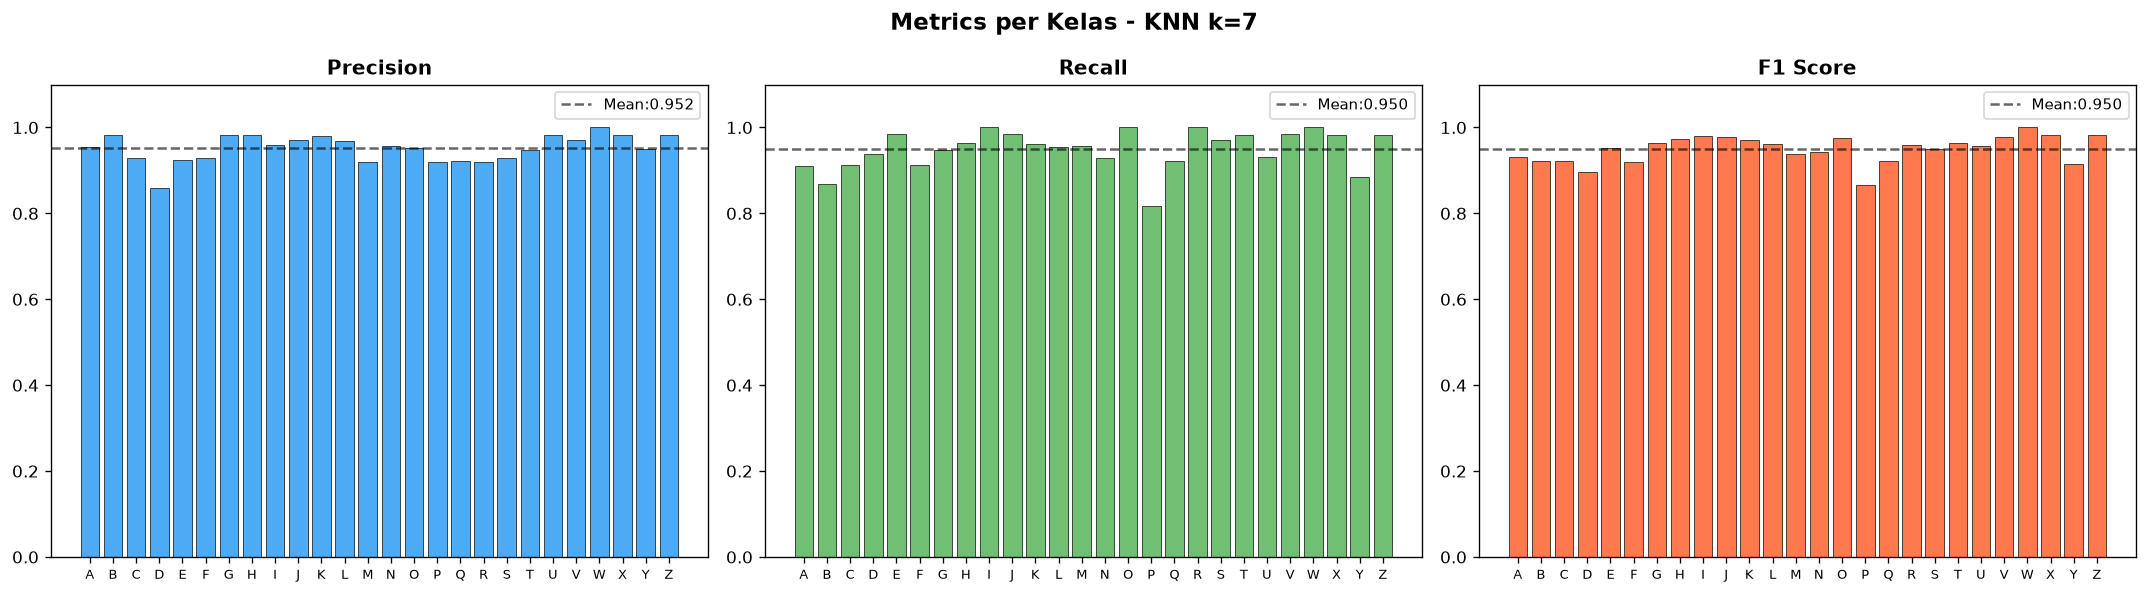

In [8]:
report=classification_report(y_test,y_pred,target_names=class_names,output_dict=True)
print(classification_report(y_test,y_pred,target_names=class_names))
fig,axes=plt.subplots(1,3,figsize=(18,5))
for ax,metric,color in zip(axes,['precision','recall','f1-score'],['#2196F3','#4CAF50','#FF5722']):
    vals=[report[cls][metric] for cls in class_names]
    ax.bar(class_names,vals,color=color,alpha=0.8,edgecolor='black',lw=0.5)
    ax.axhline(np.mean(vals),color='black',ls='--',alpha=0.6,label=f'Mean:{np.mean(vals):.3f}')
    ax.set_ylim(0,1.1);ax.set_title(metric.replace('-',' ').title(),fontweight='bold')
    ax.legend(fontsize=9);ax.tick_params(axis='x',labelsize=8)
plt.suptitle('Metrics per Kelas - KNN k=7',fontsize=14,fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'metrics_per_class_knn_k7.png'),dpi=150,bbox_inches='tight')
plt.show()

## 9. Confusion Matrix

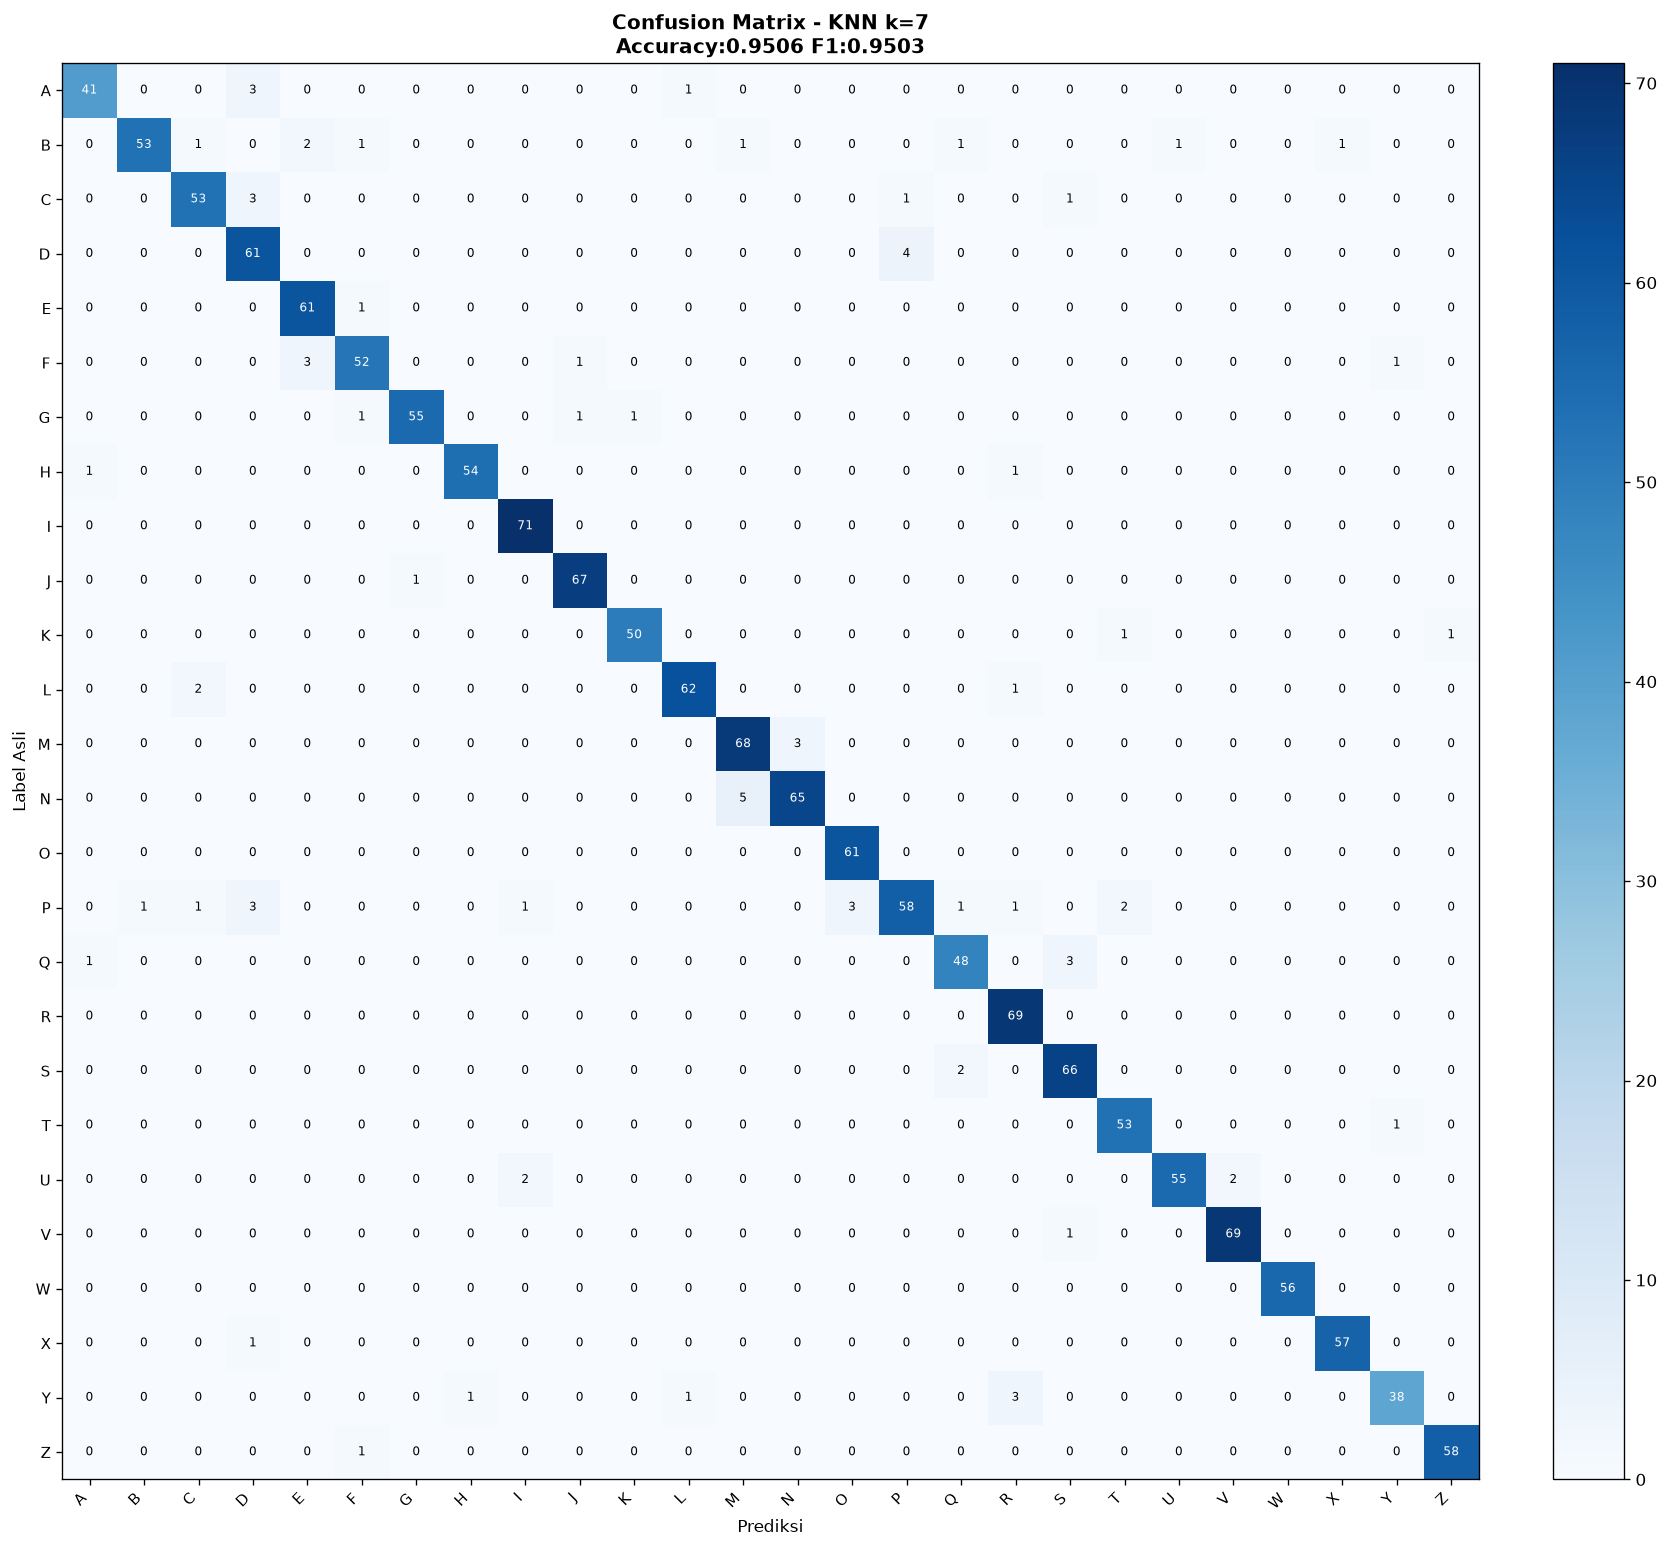

In [9]:
cm=confusion_matrix(y_test,y_pred)
fig,ax=plt.subplots(figsize=(16,13))
im=ax.imshow(cm,interpolation='nearest',cmap='Blues')
plt.colorbar(im,ax=ax,fraction=0.046,pad=0.04)
thresh=cm.max()/2
for i in range(len(class_names)):
    for j in range(len(class_names)):
        ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=7,color='white' if cm[i,j]>thresh else 'black')
ax.set_xticks(range(len(class_names)));ax.set_xticklabels(class_names,rotation=45,ha='right',fontsize=9)
ax.set_yticks(range(len(class_names)));ax.set_yticklabels(class_names,fontsize=9)
ax.set_xlabel('Prediksi');ax.set_ylabel('Label Asli')
ax.set_title(f'Confusion Matrix - KNN k=7\nAccuracy:{accuracy:.4f} F1:{f1:.4f}',fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'cm_knn_k7.png'),dpi=150,bbox_inches='tight')
plt.show()

## 10. Ringkasan

In [10]:
df_sum=pd.DataFrame([{'Algoritma':f'KNN (k=7)','Accuracy':f'{accuracy:.4f}','Precision':f'{precision:.4f}','Recall':f'{recall:.4f}','F1-Score':f'{f1:.4f}','CV F1':f'{cv_scores.mean():.4f}+/-{cv_scores.std():.4f}','Train(s)':f'{train_time:.3f}','Pred(s)':f'{pred_time:.3f}'}])
display(df_sum)
print('Notebook KNN k=7 selesai!')

,Algoritma,Accuracy,Precision,Recall,F1-Score,CV F1,Train(s),Pred(s)
0,KNN (k=7),0.9506,0.9513,0.9506,0.9503,0.9421+/-0.0027,0.073,0.258


Notebook KNN k=7 selesai!
